In [1]:
#This script loads and verifies the test dataset for the GeoGuessr project
import pandas as pd
from pathlib import Path
image_dir = Path("/work/cssema416/202710/11/datasets/OpenWorld/extracted_test")
run_name = "clip_sampler_1" # change per experiment, e.g. "clip_unbalanced"
out_dir = Path("output")/run_name
out_dir.mkdir(parents=True, exist_ok=True)

#Verifies the shape
csv_path = "/work/cssema416/202710/11/datasets/OpenWorld/test.csv"
df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

#This confirms data loaded as expected
print("Metadata rows:", len(df))
print("Metadata columns:", len(df.columns))

#nunique is num of unique elements
print("Unique countries:", df["country"].nunique())

print("Country counts:")
print(df["country"].value_counts().head())

image_files = [
    p for p in image_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg"
    }
]

print("Extracted image files:", len(image_files))
print("Example image paths:", image_files[:5])


Dataset shape: (210122, 26)
                 id   latitude  longitude  \
0   547473234108938 -16.336027  45.628280   
1   826109781317024  50.855687  56.147997   
2  1006398440000844  37.956651  14.954485   
3  2943891539215481  12.373333  -8.909906   
4   122945119799579   7.510295  99.061884   

                                  thumb_original_url country  \
0  https://scontent-cdg4-3.xx.fbcdn.net/m1/v/t6/A...      MG   
1  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      KZ   
2  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      IT   
3  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      ML   
4  https://scontent-cdg4-3.xx.fbcdn.net/m1/v/t6/A...      TH   

                 sequence    captured_at  lon_bin  lat_bin      cell  ...  \
0  Z2sJMyDVAtHBu7UFGvnYXg  1660909818797       61       28  (61, 28)  ...   
1  6cTpNBSYQH6SeDsfz_0mEQ  1548919530404       64       78  (64, 78)  ...   
2  xhcEpYg3dKnzts5ejIiSBJ  1658912403000       53       68  (53, 68)  ...   
3  j6nwj

In [2]:
from pathlib import Path

# Find images inside extracted_test and all its subfolders
image_lookup = {
    p.stem: str(p)
    for p in image_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg"}
}

# Match image IDs to the CSV
df["id"] = df["id"].astype(str).str.strip()
df["image_path"] = df["id"].map(image_lookup)

print("Unique image IDs:", len(image_lookup))
print("Unique CSV IDs:", df["id"].nunique())
print("Matching IDs:", df["image_path"].notna().sum())
print("CSV IDs missing images:", df["image_path"].isna().sum())

print("\nExample matches:")
print(df[["id", "image_path", "country"]].head())

Unique image IDs: 210122
Unique CSV IDs: 210122
Matching IDs: 210122
CSV IDs missing images: 0

Example matches:
                 id                                         image_path country
0   547473234108938  /work/cssema416/202710/11/datasets/OpenWorld/e...      MG
1   826109781317024  /work/cssema416/202710/11/datasets/OpenWorld/e...      KZ
2  1006398440000844  /work/cssema416/202710/11/datasets/OpenWorld/e...      IT
3  2943891539215481  /work/cssema416/202710/11/datasets/OpenWorld/e...      ML
4   122945119799579  /work/cssema416/202710/11/datasets/OpenWorld/e...      TH


In [3]:
print(df["country"].value_counts().to_string())

country
US    23875
RU    14984
AU    11052
BR    10425
CA     9580
IN     6525
MX     4759
CN     4404
AR     4260
KZ     3883
TR     3537
CD     3270
ZA     2969
NO     2771
TH     2682
NZ     2653
ID     2628
ZM     2491
ES     2470
CL     2447
PH     2440
FI     2280
JP     2128
PE     2114
SE     2105
FR     2047
ET     1937
MZ     1874
IR     1832
BW     1787
CO     1746
DZ     1655
TM     1635
TZ     1602
PG     1546
IT     1508
GB     1491
MG     1478
AO     1477
BO     1429
NG     1413
MY     1399
PK     1357
MA     1266
CM     1237
ML     1226
IS     1209
DE     1204
PL     1134
VN     1091
BY     1071
MM     1043
SA     1010
EG      989
GR      983
UG      837
GH      835
TN      829
CU      812
RO      803
MW      775
OM      771
UZ      764
PT      689
IE      623
MN      621
KR      616
BD      606
EC      596
LK      571
VU      522
KG      515
LA      510
CR      505
YE      497
SN      493
BG      473
CF      467
CI      460
TD      458
KE      458
TJ      451
NI      

In [4]:
baseline_country = "US" #this was the highest occuring country in dataset

data = df["country"]
y_pred = [baseline_country] * len(data)

accuracy = (data == y_pred).mean()

print("Baseline country:", baseline_country)
print("Baseline accuracy:", accuracy)
print("Number of images:", len(data))
print("Number of correct guesses:", len(data) * accuracy)
print("Number of countries:", data.nunique())

Baseline country: US
Baseline accuracy: 0.11362446578654306
Number of images: 210122
Number of correct guesses: 23875.0
Number of countries: 219


In [5]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
from transformers import CLIPModel

transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4815, 0.4578, 0.4082], std=[0.2686, 0.2613, 0.2758]),
])

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

class ClipClassifier(nn.Module):
    def __init__(self, clip, num_classes):
        super().__init__()
        self.clip = clip
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        with torch.no_grad():
            pooled = self.clip.vision_model(pixel_values=x).pooler_output
            feats = self.clip.visual_projection(pooled)
        return self.fc(feats)

model = ClipClassifier(clip, df["country"].nunique())

print(model)

/home/kennym1/miniconda3/envs/CSSE416/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 17760.37it/s]

ClipClassifier(
  (clip): CLIPModel(
    (text_model): CLIPTextModel(
      (embeddings): CLIPTextEmbeddings(
        (token_embedding): Embedding(49408, 512)
        (position_embedding): Embedding(77, 512)
      )
      (encoder): CLIPEncoder(
        (layers): ModuleList(
          (0-11): 12 x CLIPEncoderLayer(
            (self_attn): CLIPAttention(
              (k_proj): Linear(in_features=512, out_features=512, bias=True)
              (v_proj): Linear(in_features=512, out_features=512, bias=True)
              (q_proj): Linear(in_features=512, out_features=512, bias=True)
              (out_proj): Linear(in_features=512, out_features=512, bias=True)
            )
            (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
            (mlp): CLIPMLP(
              (activation_fn): QuickGELUActivation()
              (fc1): Linear(in_features=512, out_features=2048, bias=True)
              (fc2): Linear(in_features=2048, out_features=512, bias=Tr

In [6]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["country_label"] = label_encoder.fit_transform(df["unique_country"])

num_countries = len(label_encoder.classes_)

print("Number of countries:", num_countries)
print("Country classes:", label_encoder.classes_)

Number of countries: 219
Country classes: ['AE' 'AF' 'AG' 'AI' 'AL' 'AM' 'AO' 'AR' 'AT' 'AU' 'AW' 'AX' 'AZ' 'BA'
 'BB' 'BD' 'BE' 'BF' 'BG' 'BH' 'BI' 'BJ' 'BM' 'BN' 'BO' 'BQ' 'BR' 'BS'
 'BT' 'BW' 'BY' 'BZ' 'CA' 'CD' 'CF' 'CG' 'CH' 'CI' 'CL' 'CM' 'CN' 'CO'
 'CR' 'CU' 'CV' 'CW' 'CX' 'CY' 'CZ' 'DE' 'DJ' 'DK' 'DM' 'DO' 'DZ' 'EC'
 'EE' 'EG' 'ER' 'ES' 'ET' 'FI' 'FJ' 'FK' 'FM' 'FO' 'FR' 'GA' 'GB' 'GD'
 'GE' 'GF' 'GG' 'GH' 'GL' 'GM' 'GN' 'GP' 'GQ' 'GR' 'GT' 'GW' 'GY' 'HK'
 'HN' 'HR' 'HT' 'HU' 'ID' 'IE' 'IL' 'IM' 'IN' 'IQ' 'IR' 'IS' 'IT' 'JE'
 'JM' 'JO' 'JP' 'KE' 'KG' 'KH' 'KI' 'KM' 'KN' 'KP' 'KR' 'KW' 'KY' 'KZ'
 'LA' 'LB' 'LC' 'LK' 'LR' 'LS' 'LT' 'LU' 'LV' 'LY' 'MA' 'MD' 'ME' 'MF'
 'MG' 'MK' 'ML' 'MM' 'MN' 'MQ' 'MR' 'MS' 'MT' 'MU' 'MV' 'MW' 'MX' 'MY'
 'MZ' 'NC' 'NE' 'NG' 'NI' 'NL' 'NO' 'NP' 'NZ' 'OM' 'PA' 'PE' 'PF' 'PG'
 'PH' 'PK' 'PL' 'PR' 'PS' 'PT' 'PW' 'PY' 'QA' 'RE' 'RO' 'RS' 'RU' 'RW'
 'SA' 'SB' 'SD' 'SE' 'SG' 'SI' 'SJ' 'SK' 'SL' 'SN' 'SO' 'SR' 'SS' 'ST'
 'SV' 'SX' 'SY' 'SZ' 'TC' 'TD' 'TG'

In [9]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
 
device = "cuda" if torch.cuda.is_available() else "cpu"
 
sub = df.sample(n=20_000, random_state=0)

sub_counts = sub["country_label"].value_counts()
sub = sub[sub["country_label"].isin(sub_counts[sub_counts >= 20].index)]

tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(sub, groups=sub["sequence"]))
train_df, test_df = sub.iloc[tr], sub.iloc[te]
 
class GeoDataset(Dataset):
    def __init__(self, frame):
        self.paths = frame["image_path"].tolist()
        self.labels = frame["country_label"].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

class_counts = train_df["country_label"].value_counts()
sample_weights = train_df["country_label"].map(lambda c: 1.0/class_counts[c]).tolist()
sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_df), replacement=True)
 
train_loader = DataLoader(GeoDataset(train_df), batch_size=128, sampler=sampler, num_workers=8)
test_loader  = DataLoader(GeoDataset(test_df),  batch_size=128, shuffle=False, num_workers=8)
 
for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True
model = model.to(device)
 
optimizer = torch.optim.AdamW(model.fc.parameters(), lr=.001)
loss_fn = nn.CrossEntropyLoss()

train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(5):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = loss_fn(out, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (out.argmax(1) == y).sum().item()
        total += len(y)
    train_losses.append(total_loss/len(train_loader))
    train_accs.append(correct/total)

    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += loss_fn(out, y).item()
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    test_losses.append(total_loss/len(test_loader))
    test_accs.append(correct/total)

    print(f"epoch {epoch+1}: train acc {train_accs[-1]:.3f}, test acc {test_accs[-1]:.3f}")
 
torch.save(model.fc.state_dict(), out_dir/"clip_fc_country.pt")

epoch 1: train acc 0.455, test acc 0.370
epoch 2: train acc 0.533, test acc 0.408
epoch 3: train acc 0.577, test acc 0.439
epoch 4: train acc 0.612, test acc 0.451
epoch 5: train acc 0.641, test acc 0.467


In [10]:
from sklearn.metrics import balanced_accuracy_score

y_true = []
y_pred = []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

majority = train_df["country_label"].mode()[0]
baseline_acc = (test_df["country_label"] == majority).mean()

print("Accuracy:", sum(t == p for t, p in zip(y_true, y_pred))/len(y_true))
print("Baseline accuracy:", baseline_acc)
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

Accuracy: 0.4666314956475864
Baseline accuracy: 0.11738327618042733
Balanced accuracy: 0.48384449411167874


In [ ]:
import json
import numpy as np

json.dump({
    "train_losses": train_losses, "test_losses": test_losses,
    "train_accs": train_accs,     "test_accs": test_accs,
    "baseline_acc": float(baseline_acc),
    "accuracy": sum(t == p for t, p in zip(y_true, y_pred))/len(y_true),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
}, open(out_dir/"history.json", "w"))

np.savez(out_dir/"preds.npz", y_true=np.array(y_true), y_pred=np.array(y_pred), classes=label_encoder.classes_)

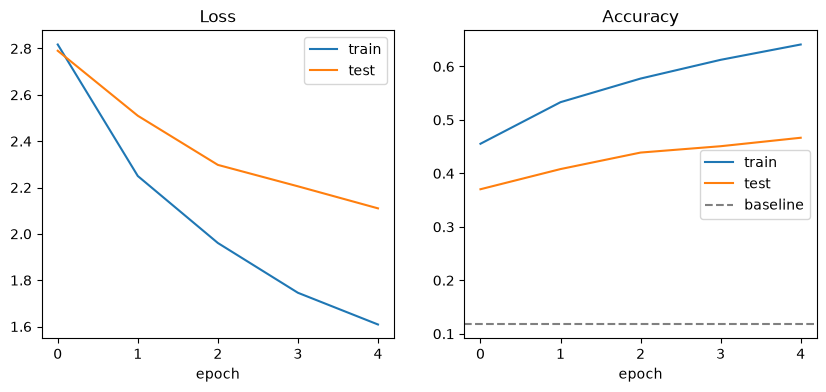

In [11]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="train")
plt.plot(test_losses, label="test")
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="train")
plt.plot(test_accs, label="test")
plt.axhline(baseline_acc, color="gray", linestyle="--", label="baseline")
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.savefig(out_dir/"curves.png", dpi=150, bbox_inches="tight")
plt.show()